# Part E: hardware comparison (CORE suite)

Compares the CORE runs from the four machines. Uses the original code (before) for the counter check and the fixed code (after) for everything else. Medians over 5 replicates.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
d = pd.read_csv("../results/timings.csv")
d["us_per_op"] = d.total_ns / d.n_ops / 1000
core = d[d.experiment == "CORE"].copy()
core["op"] = core.operation + "_" + core.n_keys.astype(str)
# One code version per machine. The index code is identical within each set (git diff on indexes/ is empty).
AFTER  = {"zaid-mbp": "27f58fb", "vivian-mbp": "e7a1255", "oscar-omen": "584f39d", "ike-mba": "c2b371c"}
BEFORE = {"zaid-mbp": "8de0f60", "vivian-mbp": "a590d16", "oscar-omen": "5fdac67", "ike-mba": "5fdac67"}
pick = lambda M: core[[v == M[m] for m, v in zip(core.machine_id, core.code_version)]]
before, after = pick(BEFORE), pick(AFTER)
machines = pd.read_csv("../machines.csv")
machines[["machine_id", "computer_model", "cpu_model", "cpu_cores", "ram_gb", "docker_cpus", "docker_memory_gb", "power"]]

,machine_id,computer_model,cpu_model,cpu_cores,ram_gb,docker_cpus,docker_memory_gb,power
0,zaid-mbp,"MacBook Pro 16"" 2023",Apple M3 Pro,12,18,12,8,plugged in
1,vivian-mbp,"MacBook Pro 14"" 2023",Apple M3,8,16,8,8,plugged in
2,oscar-omen,HP Omen Transcend 14,Intel Core Ultra 7 155H,16,16,16,8,plugged in
3,ike-mba,"MacBook Air 13"" 2025",Apple M4,10,24,10,8,battery


## Q1. Are the counters identical across machines?

In [2]:
COUNTERS = ["comparisons", "nodes_visited", "rotations", "splits", "resizes", "height"]
rows = []
for name, x in [("before", before), ("after", after)]:
    bad = 0; total = 0
    for (ix, op), g in x.groupby(["index_type", "op"]):
        for col in COUNTERS:
            total += 1
            bad += g[col].fillna(-1).nunique() > 1
    rows.append({"code": name, "rows": len(x), "configs x counters": total, "differing across machines/reps": bad})
pd.DataFrame(rows)

,code,rows,configs x counters,differing across machines/reps
0,before,1050,252,0
1,after,840,252,0


## Q2. Fastest vs slowest machine

In [3]:
med = after.groupby(["index_type", "op", "machine_id"]).us_per_op.median().unstack()
ratio = (med.max(axis=1) / med.min(axis=1)).unstack()
ratio = ratio[["build_10000", "build_114000", "point_hit_114000", "point_miss_114000", "range_114000", "prefix_113999"]]
print("slowest/fastest median ratio, per index and operation")
display(ratio.round(2))
print("fastest machine count:", med.idxmin(axis=1).value_counts().to_dict())
print("slowest machine count:", med.idxmax(axis=1).value_counts().to_dict())
print("ratio by operation (min / median / max over indexes):")
display(ratio.agg(["min", "median", "max"]).round(2))

slowest/fastest median ratio, per index and operation


op,build_10000,build_114000,point_hit_114000,point_miss_114000,range_114000,prefix_113999
index_type,,,,,,
avl_tree,2.23,2.36,2.69,2.30,4.13,3.08
bplus_tree,2.15,2.55,2.46,2.07,4.67,3.38
hash_table,2.74,2.88,2.56,2.44,3.37,3.54
ref_bisect,1.78,1.93,1.79,2.20,2.49,2.38
ref_dict,1.86,2.57,2.30,2.25,1.96,3.18
sorted_list,1.91,1.80,2.11,1.91,3.84,3.04
unsorted_list,1.68,1.81,1.91,1.47,1.86,2.33


fastest machine count: {'ike-mba': 41, 'vivian-mbp': 1}
slowest machine count: {'oscar-omen': 33, 'vivian-mbp': 5, 'zaid-mbp': 4}
ratio by operation (min / median / max over indexes):


op,build_10000,build_114000,point_hit_114000,point_miss_114000,range_114000,prefix_113999
min,1.68,1.80,1.79,1.47,1.86,2.33
median,1.91,2.36,2.30,2.20,3.37,3.08
max,2.74,2.88,2.69,2.44,4.67,3.54


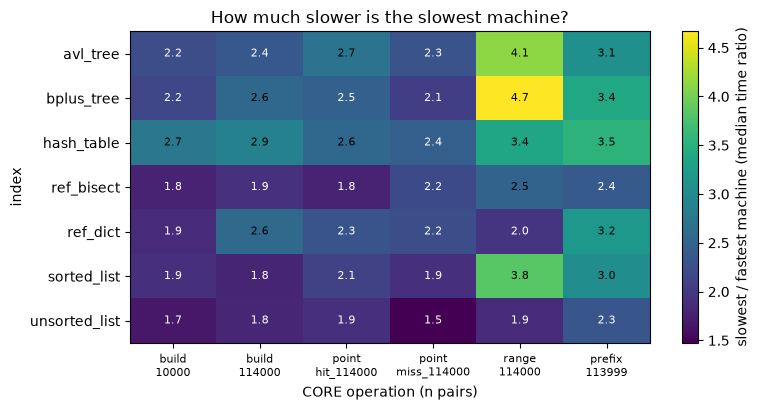

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(ratio.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(ratio.shape[1])); ax.set_xticklabels([c.replace("_", "\n", 1) for c in ratio.columns], fontsize=8)
ax.set_yticks(range(ratio.shape[0])); ax.set_yticklabels(ratio.index)
for i in range(ratio.shape[0]):
    for j in range(ratio.shape[1]):
        v = ratio.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", color="white" if v < ratio.values.mean() else "black", fontsize=8)
ax.set_xlabel("CORE operation (n pairs)"); ax.set_ylabel("index")
fig.colorbar(im, ax=ax, label="slowest / fastest machine (median time ratio)")
ax.set_title("How much slower is the slowest machine?")
fig.tight_layout(); fig.savefig("../report/figures/hardware/PartE_machine_ratio_heatmap.png", dpi=200); plt.show()

## Q3. Does the ranking of indexes change between machines?

In [5]:
rank_rows = []
for op, g in med.groupby(level=1):
    g = g.droplevel(1)
    orders = {m: tuple(g[m].sort_values().index) for m in g.columns}
    distinct = set(orders.values())
    rank_rows.append({"operation": op, "distinct orderings (of 4 machines)": len(distinct)})
display(pd.DataFrame(rank_rows))
main = ["unsorted_list", "sorted_list", "hash_table", "avl_tree", "bplus_tree"]
for op, g in med.groupby(level=1):
    g = g.droplevel(1).loc[main]
    orders = {m: " < ".join(g[m].sort_values().index) for m in g.columns}
    if len(set(orders.values())) > 1:
        print(op); [print("  ", m, ":", o) for m, o in orders.items()]

,operation,distinct orderings (of 4 machines)
0,build_10000,2
1,build_114000,2
2,point_hit_114000,2
3,point_miss_114000,2
4,prefix_113999,2
5,range_114000,2


point_hit_114000
   ike-mba : hash_table < avl_tree < bplus_tree < sorted_list < unsorted_list
   oscar-omen : hash_table < avl_tree < sorted_list < bplus_tree < unsorted_list
   vivian-mbp : hash_table < avl_tree < sorted_list < bplus_tree < unsorted_list
   zaid-mbp : hash_table < avl_tree < sorted_list < bplus_tree < unsorted_list
point_miss_114000
   ike-mba : hash_table < avl_tree < bplus_tree < sorted_list < unsorted_list
   oscar-omen : hash_table < avl_tree < bplus_tree < sorted_list < unsorted_list
   vivian-mbp : hash_table < avl_tree < bplus_tree < sorted_list < unsorted_list
   zaid-mbp : hash_table < avl_tree < sorted_list < bplus_tree < unsorted_list
prefix_113999
   ike-mba : bplus_tree < sorted_list < avl_tree < unsorted_list < hash_table
   oscar-omen : sorted_list < bplus_tree < avl_tree < unsorted_list < hash_table
   vivian-mbp : bplus_tree < sorted_list < avl_tree < unsorted_list < hash_table
   zaid-mbp : bplus_tree < sorted_list < avl_tree < unsorted_list < hash_

## Q4. Variability: coefficient of variation over the 5 replicates

In [6]:
cv = after.groupby(["machine_id", "index_type", "op"]).us_per_op.agg(lambda s: s.std(ddof=1) / s.mean() * 100).unstack(0)
display(cv.agg(["median", "mean", "max"]).round(1))
print("top noisy configurations:")
display(cv.stack().sort_values(ascending=False).head(8).round(1))
x = after.assign(batch_ms=after.total_ns / 1e6)
g = x.groupby(["machine_id", "index_type", "op"]).agg(cv=("us_per_op", lambda s: s.std(ddof=1) / s.mean() * 100), ms=("batch_ms", "median")).reset_index()
display(g.assign(batch_under_5ms=g.ms < 5).groupby("batch_under_5ms").cv.agg(["median", "mean", "count"]).round(1))

machine_id,ike-mba,oscar-omen,vivian-mbp,zaid-mbp
median,3.5,7.8,2.4,8.2
mean,9.6,9.6,2.9,14.1
max,67.3,25.6,9.7,79.8


top noisy configurations:


index_type     op                 machine_id
ref_bisect     point_hit_114000   zaid-mbp      79.8
unsorted_list  build_10000        ike-mba       67.3
avl_tree       point_miss_114000  zaid-mbp      63.2
               point_hit_114000   zaid-mbp      52.0
ref_dict       build_114000       zaid-mbp      46.0
unsorted_list  build_114000       ike-mba       45.1
               range_114000       ike-mba       37.8
sorted_list    range_114000       ike-mba       36.6
dtype: float64

,median,mean,count
batch_under_5ms,,,
False,3.9,7.8,107
True,5.7,11.3,61


## Q5. Memory per index (E1 `memory_bytes`, 114,000 pairs)

In [7]:
e1 = d[(d.experiment == "E1_build_memory") & (d.operation == "build") & (d.n_keys == 114000)]
mem = e1[e1.code_version.isin(["584f39d", "af79e03"])].groupby(["index_type", "machine_id"]).memory_bytes.median().unstack() / 2**20
mem["bytes_per_pair"] = (mem["oscar-omen"] * 2**20 / 114000).round(0)
mem["pairs_in_8GiB"] = (8 * 1024 / mem["oscar-omen"] * 114000 / 1e6).round(0)
print("MiB of added structure memory. vivian-mbp's run is pre-fix code (af79e03), so only the hash table differs.")
mem.round(2)

MiB of added structure memory. vivian-mbp's run is pre-fix code (af79e03), so only the hash table differs.


machine_id,oscar-omen,vivian-mbp,bytes_per_pair,pairs_in_8GiB
index_type,,,,
avl_tree,12.53,12.53,115.0,75.0
bplus_tree,8.73,8.73,80.0,107.0
hash_table,21.23,20.45,195.0,44.0
ref_bisect,7.89,7.89,73.0,118.0
ref_dict,10.03,10.03,92.0,93.0
sorted_list,7.89,7.89,73.0,118.0
unsorted_list,7.06,7.06,65.0,132.0
